In [13]:
%mamba install pandas numpy matplotlib scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.179 seconds
All requested packages already installed.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Palmer Penguins dataset
df = sns.load_dataset('penguins')

# Display beginning and end
display(df.head())
display(df.tail())

# Record shape and info
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


Rows: 344, Columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 14.9 KB


In [4]:
# Separate numerical and categorical columns (including 'str' to avoid the Pandas warning)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'str', 'category', 'bool']).columns

print("Numerical Summary:")
display(df[num_cols].describe())

Numerical Summary:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [5]:
print("Missing Values Count:")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

print("\nMissing Values Percentage:")
missing_percent = (df.isnull().mean() * 100).round(2)
print(missing_percent[missing_percent > 0])

Missing Values Count:
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Missing Values Percentage:
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
dtype: float64


In [6]:
# Make a copy before modifying
df_clean = df.copy()

# The missing values are in the physical measurements and the 'sex' column.
# Impute numerical columns with the median
cols_to_impute_median = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
for col in cols_to_impute_median:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# Impute categorical 'sex' column with the mode (most frequent)
sex_mode = df_clean['sex'].mode()[0]
df_clean['sex'] = df_clean['sex'].fillna(sex_mode)

# Verify missing values are resolved
print("Remaining missing values:", df_clean.isnull().sum().sum())

Remaining missing values: 0


In [7]:
# Identify duplicates
duplicates = df_clean.duplicated().sum()
print(f"Duplicate rows found: {duplicates}")

# Remove duplicates (if any exist)
df_clean = df_clean.drop_duplicates()

# Check categorical consistency
print("Species categories:", df_clean['species'].unique())
print("Island categories:", df_clean['island'].unique())
print("Sex categories:", df_clean['sex'].unique())

Duplicate rows found: 0
Species categories: <StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str
Island categories: <StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
Sex categories: <StringArray>
['Male', 'Female']
Length: 2, dtype: str


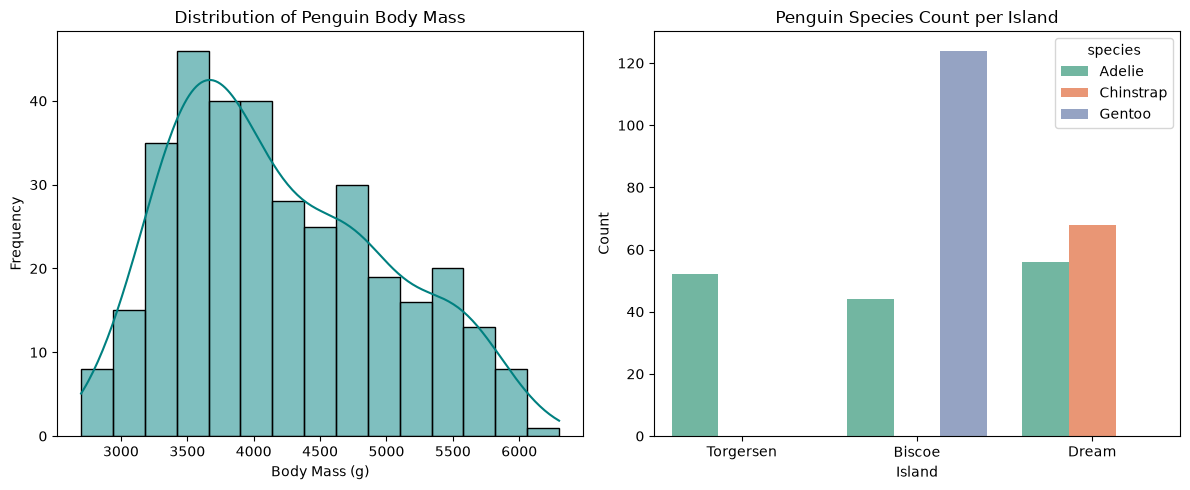

In [8]:
plt.figure(figsize=(12, 5))

# Visualisation 1: Histogram of Body Mass
plt.subplot(1, 2, 1)
sns.histplot(df_clean['body_mass_g'], bins=15, kde=True, color='teal')
plt.title('Distribution of Penguin Body Mass')
plt.xlabel('Body Mass (g)')
plt.ylabel('Frequency')

# Visualisation 2: Bar chart of Species by Island
plt.subplot(1, 2, 2)
sns.countplot(data=df_clean, x='island', hue='species', palette='Set2')
plt.title('Penguin Species Count per Island')
plt.xlabel('Island')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [9]:
# Assuming 'species' is our target variable for a future ML model, we leave it unencoded for now.
# We will apply One-Hot Encoding to the input features: 'island' and 'sex'
df_encoded = pd.get_dummies(df_clean, columns=['island', 'sex'], drop_first=True)

# Convert boolean columns to integers (0 and 1) for machine learning compatibility
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

display(df_encoded.head())

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_Male
0,Adelie,39.10,18.7,181.0,3750.0,0,1,1
1,Adelie,39.50,17.4,186.0,3800.0,0,1,0
2,Adelie,40.30,18.0,195.0,3250.0,0,1,0
3,Adelie,44.45,17.3,197.0,4050.0,0,1,1
4,Adelie,36.70,19.3,193.0,3450.0,0,1,0


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols_to_scale = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Apply standard scaling (mean=0, variance=1) to the numerical features
df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])

display(df_encoded.head())

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_Male
0,Adelie,-0.887622,0.787289,-1.420541,-0.564625,0,1,1
1,Adelie,-0.814037,0.126114,-1.063485,-0.502010,0,1,0
2,Adelie,-0.666866,0.431272,-0.420786,-1.190773,0,1,0
3,Adelie,0.096581,0.075255,-0.277964,-0.188936,0,1,1
4,Adelie,-1.329133,1.092447,-0.563608,-0.940314,0,1,0


In [11]:
# Verify final shape and nulls
print(f"Final shape: {df_encoded.shape}")
print(f"Remaining nulls: {df_encoded.isnull().sum().sum()}")

# Save to CSV
final_filename = 'penguins_prepared.csv'
df_encoded.to_csv(final_filename, index=False)
print(f"Dataset successfully saved as '{final_filename}'")

Final shape: (344, 8)
Remaining nulls: 0
Dataset successfully saved as 'penguins_prepared.csv'
